### Hosted MCP Tool with Microsoft Agent Framework

## Visual workflow

Read this from top to bottom: configuration creates the agent and registers the MCP capability; the query then enters a human-approval loop before the final response is printed.

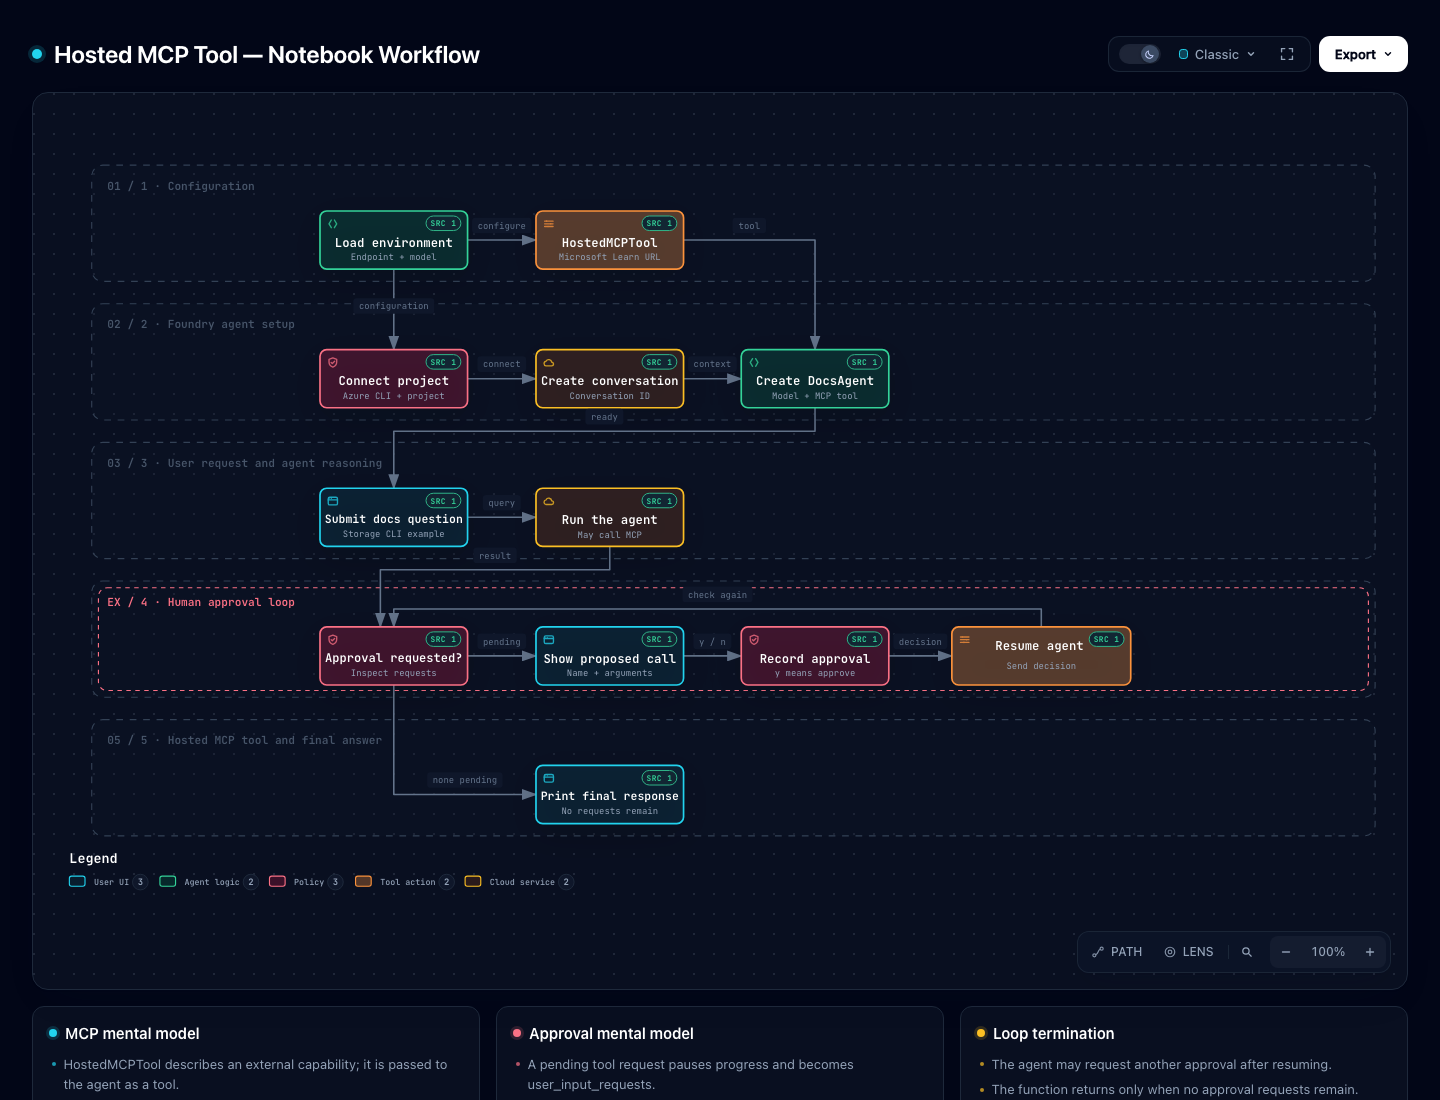

[Open the interactive Archify workflow](../../.archify/workflow-mcp-tool-notebook-20261030-152507/mcp-tool-workflow.html)

![MCP_Lab](./Assets/MCP_Lab.png)

In [ ]:
# Install the exact Agent Framework and Foundry SDK versions used by this notebook.
# %pip installs them into the Python environment used by the current Jupyter kernel.
%pip install agent-framework==1.0.0b251209 python-dotenv azure-ai-projects==2.0.0b2

### Setting Up the Environment

In [ ]:
# Read configuration values from the environment instead of hard-coding project details.
# os reads environment variables; load_dotenv also loads values from a local .env file.
import os
from dotenv import load_dotenv
from azure.core.credentials import AzureKeyCredential

load_dotenv()
project_endpoint = os.getenv("AI_FOUNDRY_PROJECT_ENDPOINT")
model = os.getenv("AI_FOUNDRY_DEPLOYMENT_NAME")

print("Project Endpoint: ", project_endpoint)
print("Model: ", model)

### Creating our MS Learn MCP Tool Object

In [ ]:
# HostedMCPTool is a description of a remote MCP capability, not an immediate tool call.
# The agent receives this object later and decides when the Microsoft Learn tool is useful.
from agent_framework import HostedMCPTool

ms_learn_mcp_tool = HostedMCPTool(
    name = "Microsoft Learn MCP Tool",
    url = "https://learn.microsoft.com/api/mcp"
)

### Creating our MCP Agent

In [ ]:
# These async clients connect the notebook to the Foundry project and agent runtime.
# AzureCliCredential reuses the identity authenticated through the Azure CLI.
from agent_framework.azure import AzureAIClient
from azure.identity.aio import AzureCliCredential
from azure.ai.projects.aio import AIProjectClient

# async def allows this function to pause at await without blocking the notebook runtime.
async def create_mcp_tool_agent():
    # Create the credential object now; Azure obtains tokens when a client needs them.
    credential = AzureCliCredential()
    
    # creating the Foundry Project Client
    project_client = AIProjectClient(
        endpoint=project_endpoint,
        credential=credential
    )

    # creating a conversation using the OpenAI Client
    # Get the model/conversation client associated with this Foundry project.
    openai_client = project_client.get_openai_client()
    # Pause here until Foundry creates server-side conversation state and returns its ID.
    conversation = await openai_client.conversations.create()
    conversation_id = conversation.id
    print("Conversation ID: ", conversation_id)
    
    # creating the Azure AI Client to interact with the Agent in Foundry
    agent_client = AzureAIClient(
        project_client = project_client,
        conversation_id = conversation_id,
        model_deployment_name=model
    )
    
    # creating an agent in Foundry
    agent = agent_client.create_agent(
        name="DocsAgent",
        instructions="You are a helpful assistant that can help with Microsoft documentation questions.",
        # Register the MCP capability; this does not call Microsoft Learn yet.
        tools = [ms_learn_mcp_tool]
    )
    # Return all three objects so code outside this function can keep using and later close them.
    return agent, credential, agent_client

agent, credential, agent_client = await create_mcp_tool_agent()

### Creating an Async Function to Handle User Approvals

In [ ]:
# ChatMessage carries the structured approve/deny response back to the agent.
# The helper keeps running the same agent until no tool approval requests remain.
from agent_framework import ChatMessage

async def handle_approvals_with_thread(query: str, agent):
    # The first run either finishes or pauses with one or more approval requests.
    result = await agent.run(query)
    # Use while—not if—because resuming the agent can produce another request.
    while len(result.user_input_requests) > 0:
        # Collect structured responses for every request in the current batch.
        new_input = []
        # Each item describes the exact function call that needs a human decision.
        for user_input_needed in result.user_input_requests:
            print(
                f"\n⚙️ Function call requested: {user_input_needed.function_call.name}"
                f"\nArguments: {user_input_needed.function_call.arguments}"
            )
            # input pauses normal Python execution until the user types a decision.
            user_approval = input("Approve function call? (y/n): ")
            new_input.append(
                ChatMessage(
                    role="user",
                    # Convert y to True and bind that decision to this specific request.
                    contents=[user_input_needed.create_response(user_approval.lower() == "y")],
                )
            )
        # Resume the same agent with the decisions, then inspect its new result again.
        result = await agent.run(new_input)
    return result

In [ ]:
# Ask a documentation question, let the helper handle any approval pauses, then print the result.
query = "How to create an Azure storage account using az cli?"
response = await handle_approvals_with_thread(query, agent)

print("\n🧠 Assistant:\n", response)